# MNIST Autoencoders
Simple examples of compression, denoising, and image generation using PyTorch.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
batch_size = 256
epochs = 25


## 1. Load MNIST

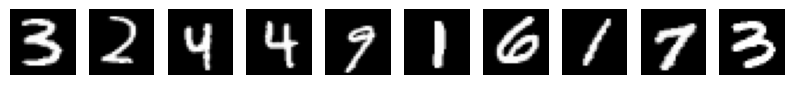

In [2]:
transform = transforms.ToTensor()

train_data = datasets.MNIST("data", train=True, download=True, transform=transform)
test_data = datasets.MNIST("data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size)

images, labels = next(iter(train_loader))
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(images[i][0], cmap="gray")
    plt.axis("off")
plt.show()


## 2. Vanilla Autoencoder

Epoch 1: loss = 0.0666
Epoch 2: loss = 0.0377
Epoch 3: loss = 0.0276
Epoch 4: loss = 0.0243
Epoch 5: loss = 0.0215
Epoch 6: loss = 0.0191
Epoch 7: loss = 0.0171
Epoch 8: loss = 0.0158
Epoch 9: loss = 0.0148
Epoch 10: loss = 0.0139
Epoch 11: loss = 0.0131
Epoch 12: loss = 0.0124
Epoch 13: loss = 0.0118
Epoch 14: loss = 0.0112
Epoch 15: loss = 0.0107
Epoch 16: loss = 0.0102
Epoch 17: loss = 0.0098
Epoch 18: loss = 0.0094
Epoch 19: loss = 0.0091
Epoch 20: loss = 0.0088
Epoch 21: loss = 0.0086
Epoch 22: loss = 0.0083
Epoch 23: loss = 0.0081
Epoch 24: loss = 0.0079
Epoch 25: loss = 0.0077


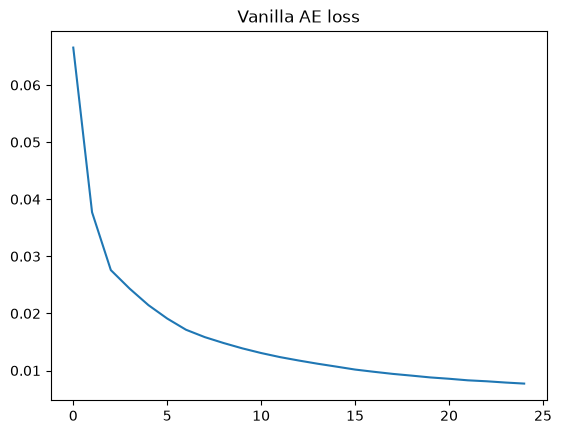

In [3]:
class VanillaAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 32)
        )
        self.decoder = nn.Sequential(
            nn.Linear(32, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


model = VanillaAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

losses = []
for epoch in range(epochs):
    total_loss = 0
    for images, _ in train_loader:
        images = images.view(-1, 784).to(device)
        output = model(images)
        loss = loss_fn(output, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    losses.append(total_loss / len(train_loader))
    print(f"Epoch {epoch+1}: loss = {losses[-1]:.4f}")

plt.plot(losses)
plt.title("Vanilla AE loss")
plt.show()


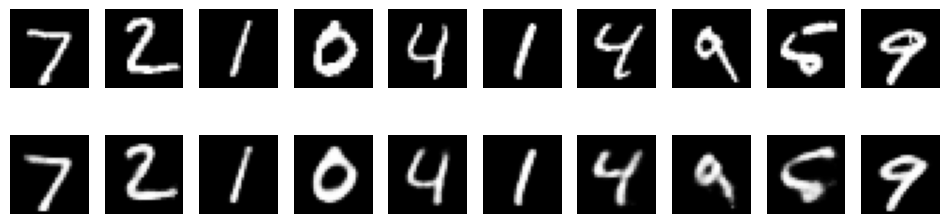

0 0.006991130765527487
1 0.0018961116438731551
2 0.011950830928981304
3 0.009346532635390759
4 0.008579944260418415
5 0.00985155999660492
6 0.008873512037098408
7 0.0062060365453362465
8 0.010796906426548958
9 0.008043838664889336


In [4]:
# Original and reconstructed images
images, labels = next(iter(test_loader))
images = images.to(device)

model.eval()
with torch.no_grad():
    rebuilt = model(images.view(-1, 784)).view(-1, 1, 28, 28)

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(images[i][0].cpu(), cmap="gray")
    plt.axis("off")
    plt.subplot(2, 10, i + 11)
    plt.imshow(rebuilt[i][0].cpu(), cmap="gray")
    plt.axis("off")
plt.show()

# Average reconstruction error for each digit
errors = ((rebuilt - images) ** 2).mean(dim=(1, 2, 3))
for digit in range(10):
    mask = labels == digit
    if mask.any():
        print(digit, errors.cpu()[mask].mean().item())


## 3. Convolutional Autoencoder

Epoch 1: loss = 0.0638
Epoch 2: loss = 0.0198
Epoch 3: loss = 0.0135
Epoch 4: loss = 0.0119
Epoch 5: loss = 0.0109
Epoch 6: loss = 0.0103
Epoch 7: loss = 0.0099
Epoch 8: loss = 0.0095
Epoch 9: loss = 0.0092
Epoch 10: loss = 0.0089
Epoch 11: loss = 0.0087
Epoch 12: loss = 0.0085
Epoch 13: loss = 0.0084
Epoch 14: loss = 0.0082
Epoch 15: loss = 0.0081
Epoch 16: loss = 0.0080
Epoch 17: loss = 0.0079
Epoch 18: loss = 0.0077
Epoch 19: loss = 0.0077
Epoch 20: loss = 0.0076
Epoch 21: loss = 0.0075
Epoch 22: loss = 0.0074
Epoch 23: loss = 0.0073
Epoch 24: loss = 0.0073
Epoch 25: loss = 0.0072


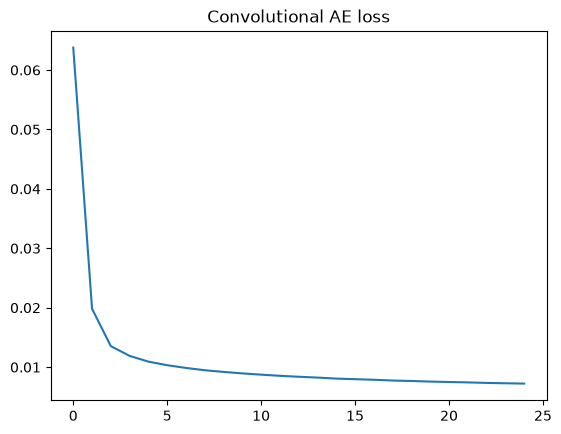

In [5]:
class ConvAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 3, 2, 1), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 16)
        )
        self.decoder = nn.Sequential(
            nn.Linear(16, 128 * 4 * 4),
            nn.Unflatten(1, (128, 4, 4)),
            nn.ConvTranspose2d(128, 64, 3, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 3, 2, 1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


conv_model = ConvAE().to(device)
optimizer = torch.optim.Adam(conv_model.parameters(), lr=0.001)
losses = []

for epoch in range(epochs):
    total_loss = 0
    for images, _ in train_loader:
        images = images.to(device)
        output = conv_model(images)
        loss = loss_fn(output, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    losses.append(total_loss / len(train_loader))
    print(f"Epoch {epoch+1}: loss = {losses[-1]:.4f}")

plt.plot(losses)
plt.title("Convolutional AE loss")
plt.show()


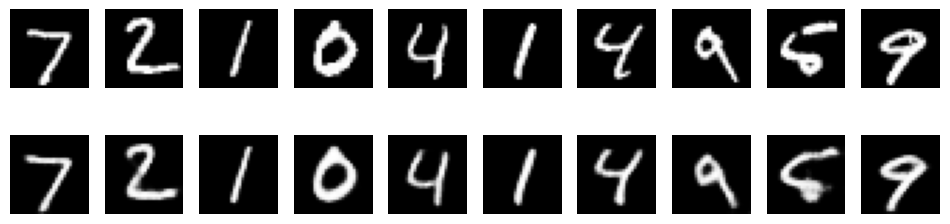

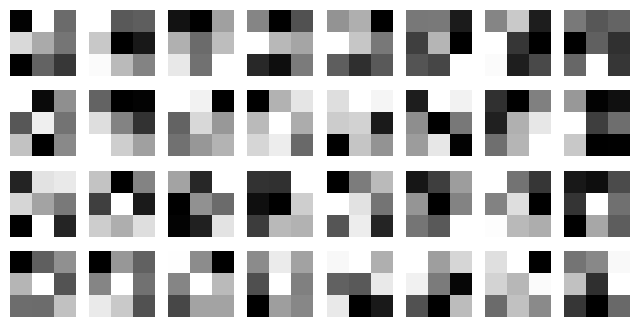

In [6]:
# Show convolutional reconstructions
images, _ = next(iter(test_loader))
images = images.to(device)
conv_model.eval()
with torch.no_grad():
    rebuilt = conv_model(images)

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(images[i][0].cpu(), cmap="gray")
    plt.axis("off")
    plt.subplot(2, 10, i + 11)
    plt.imshow(rebuilt[i][0].cpu(), cmap="gray")
    plt.axis("off")
plt.show()

# Show first-layer filters
filters = conv_model.encoder[0].weight.detach().cpu()
plt.figure(figsize=(8, 4))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(filters[i][0], cmap="gray")
    plt.axis("off")
plt.show()


## 4. Denoising Autoencoder

In [7]:
# Make noisy images
def add_noise(images, amount=0.5):
    return (images + amount * torch.randn_like(images)).clamp(0, 1)

noisy_train = add_noise(torch.stack([train_data[i][0] for i in range(len(train_data))]))
clean_train = torch.stack([train_data[i][0] for i in range(len(train_data))])

denoise_loader = DataLoader(
    torch.utils.data.TensorDataset(noisy_train, clean_train),
    batch_size=batch_size, shuffle=True
)

denoiser = ConvAE().to(device)
optimizer = torch.optim.Adam(denoiser.parameters(), lr=0.001)

for epoch in range(epochs):
    total_loss = 0
    for noisy, clean in denoise_loader:
        noisy, clean = noisy.to(device), clean.to(device)
        output = denoiser(noisy)
        loss = loss_fn(output, clean)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}: loss = {total_loss / len(denoise_loader):.4f}")


Epoch 1: loss = 0.0616
Epoch 2: loss = 0.0253
Epoch 3: loss = 0.0199
Epoch 4: loss = 0.0179
Epoch 5: loss = 0.0168
Epoch 6: loss = 0.0161
Epoch 7: loss = 0.0155
Epoch 8: loss = 0.0151
Epoch 9: loss = 0.0148
Epoch 10: loss = 0.0145
Epoch 11: loss = 0.0143
Epoch 12: loss = 0.0141
Epoch 13: loss = 0.0139
Epoch 14: loss = 0.0137
Epoch 15: loss = 0.0136
Epoch 16: loss = 0.0134
Epoch 17: loss = 0.0134
Epoch 18: loss = 0.0132
Epoch 19: loss = 0.0131
Epoch 20: loss = 0.0130
Epoch 21: loss = 0.0129
Epoch 22: loss = 0.0128
Epoch 23: loss = 0.0128
Epoch 24: loss = 0.0127
Epoch 25: loss = 0.0126


Noise 0.3: PSNR noisy=13.36, denoised=19.67 dB


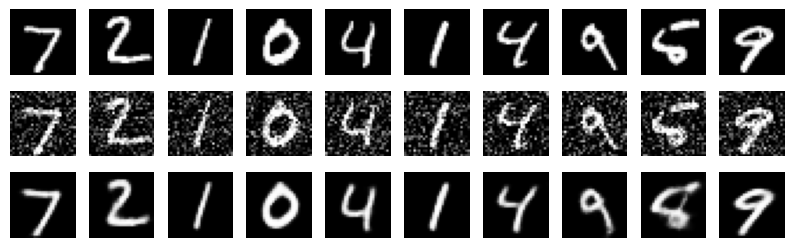

Noise 0.5: PSNR noisy=9.41, denoised=19.00 dB


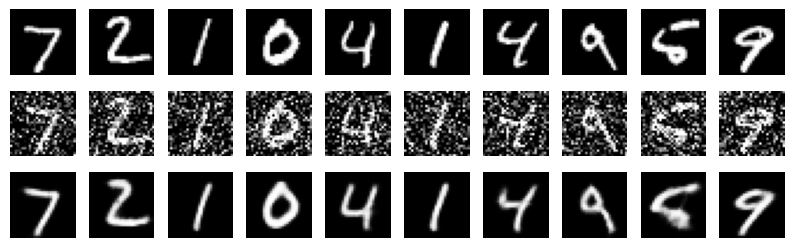

Noise 0.7: PSNR noisy=7.36, denoised=15.77 dB


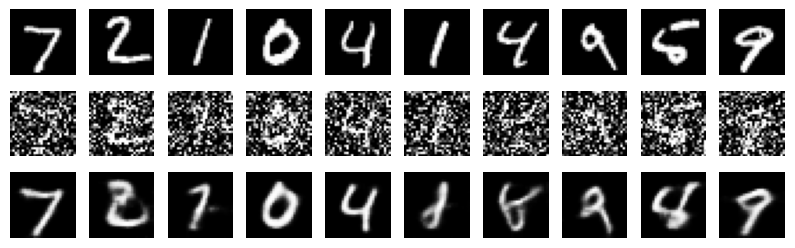

In [8]:
# Test Gaussian noise levels and show results
images, _ = next(iter(test_loader))
images = images[:10].to(device)

for level in [0.3, 0.5, 0.7]:
    noisy = add_noise(images, level)
    denoiser.eval()
    with torch.no_grad():
        clean = denoiser(noisy)

    mse_noisy = ((images - noisy) ** 2).mean()
    mse_clean = ((images - clean) ** 2).mean()
    psnr_noisy = 10 * torch.log10(1 / mse_noisy)
    psnr_clean = 10 * torch.log10(1 / mse_clean)
    print(f"Noise {level}: PSNR noisy={psnr_noisy.item():.2f}, "
          f"denoised={psnr_clean.item():.2f} dB")

    plt.figure(figsize=(10, 3))
    for i in range(10):
        plt.subplot(3, 10, i + 1)
        plt.imshow(images[i][0].cpu(), cmap="gray")
        plt.axis("off")
        plt.subplot(3, 10, i + 11)
        plt.imshow(noisy[i][0].cpu(), cmap="gray")
        plt.axis("off")
        plt.subplot(3, 10, i + 21)
        plt.imshow(clean[i][0].cpu(), cmap="gray")
        plt.axis("off")
    plt.show()


## 5. Variational Autoencoder (VAE)

In [ ]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU()
        )
        self.mu = nn.Linear(256, 2)
        self.logvar = nn.Linear(256, 2)
        self.decoder = nn.Sequential(
            nn.Linear(2, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.mu(h), self.logvar(h)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar


vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

for beta in [0.5, 1.0, 2.0]:
    vae = VAE().to(device)
    optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)
    for epoch in range(epochs):
        total_loss = 0
        for images, _ in train_loader:
            images = images.view(-1, 784).to(device)
            output, mu, logvar = vae(images)
            reconstruction = nn.functional.binary_cross_entropy(
                output, images, reduction="sum"
            )
            kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            loss = (reconstruction + beta * kl) / images.size(0)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Beta {beta}, epoch {epoch+1}: {total_loss / len(train_loader):.4f}")


Beta 0.5, epoch 1: 209.1676
Beta 0.5, epoch 2: 176.6914
Beta 0.5, epoch 3: 169.2641
Beta 0.5, epoch 4: 165.6537
Beta 0.5, epoch 5: 163.4466
Beta 0.5, epoch 6: 161.8335
Beta 0.5, epoch 7: 160.5087
Beta 0.5, epoch 8: 159.1386
Beta 0.5, epoch 9: 158.1706
Beta 0.5, epoch 10: 157.1446
Beta 0.5, epoch 11: 156.3547
Beta 0.5, epoch 12: 155.6510
Beta 0.5, epoch 13: 155.0261
Beta 0.5, epoch 14: 154.4403
Beta 0.5, epoch 15: 153.9269
Beta 0.5, epoch 16: 153.4452
Beta 0.5, epoch 17: 153.0107
Beta 0.5, epoch 18: 152.7244
Beta 0.5, epoch 19: 152.2354
Beta 0.5, epoch 20: 151.8900
Beta 0.5, epoch 21: 151.5579
Beta 0.5, epoch 22: 151.2860
Beta 0.5, epoch 23: 151.0282
Beta 0.5, epoch 24: 150.7149
Beta 0.5, epoch 25: 150.4896
Beta 1.0, epoch 1: 209.9527
Beta 1.0, epoch 2: 178.3811
Beta 1.0, epoch 3: 171.8168
Beta 1.0, epoch 4: 166.8438
Beta 1.0, epoch 5: 163.9476
Beta 1.0, epoch 6: 162.1062
Beta 1.0, epoch 7: 160.7733
Beta 1.0, epoch 8: 159.6146
Beta 1.0, epoch 9: 158.5440
Beta 1.0, epoch 10: 157.7200
Bet

In [ ]:
# Generate new digits from random latent points
vae.eval()
with torch.no_grad():
    z = torch.randn(10, 2).to(device)
    digits = vae.decoder(z).view(-1, 1, 28, 28).cpu()

plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(digits[i][0], cmap="gray")
    plt.axis("off")
plt.show()


## 6. Conclusion
Compare reconstruction images and losses. The vanilla model compresses flattened images, the convolutional model preserves image structure, the denoising model removes noise, and the VAE can generate new digits.